# Jour 2 — Prétraitement et Data Augmentation 

**Objectif du jour :** préparer les images pour le réseau de neurones, puis créer des variantes des images d'entraînement.

je vais faire 4 choses :
1. **Charger** les images par batchs et les **redimensionner** ;
2. **Normaliser** les pixels (0–255 → 0–1) ;
3. **Accélérer** le chargement avec `prefetch` ;
4. Tester la **Data Augmentation** (rotation, retournement, zoom, translation, contraste).

## Étape 1 — Importer les bibliothèques

**Problème :** on a besoin d'outils pour charger les images et faire des graphiques.

**Explication du code :**
- `tensorflow` / `keras` : la bibliothèque de Deep Learning.
- `layers` : contient les « briques » (redimensionnement, augmentation, etc.).

In [10]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow import keras 

## Étape 2 — Paramètres du projet

**Problème :** garder au même endroit les valeurs importantes pour pouvoir les changer facilement.

**Explication du code :**
- `SPLIT_DIR` : le dossier créé au Jour 1 (sur Kaggle, il est dans `/kaggle/working`).

In [ ]:
CLASSES = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

if os.path.exists("/kaggle/working"):
    SPLIT_DIR = Path("/kaggle/working/data/split")
else:
    SPLIT_DIR = Path("data/split")

# nv session 
if not SPLIT_DIR.exists() and os.path.exists("/kaggle/input"):
    for dossier, sous_dossiers, fichiers in os.walk("/kaggle/input"):
        if dossier.endswith("split") and "train" in sous_dossiers:
            SPLIT_DIR = Path(dossier)
            break

assert SPLIT_DIR.exists(), "Dossier split introuvable : exécutez d'abord le Jour 1."
print("Dossier split :", SPLIT_DIR)

Dossier split : data/split


## Étape 3 — Charger les images (redimensionnement + batchs)

**Problème :** on ne peut pas mettre 14 000 images en mémoire d'un coup, et le réseau a besoin d'images **toutes de la même taille**.

**Explication du code :** la fonction `image_dataset_from_directory` fait tout le travail :
- elle lit les images dans les sous-dossiers (le **nom du dossier = la classe**) ;
- elle les **redimensionne** avec `image_size` ;
- elle les range par **batchs** avec `batch_size` ;
- `label_mode="int"` : la classe devient un nombre (0 à 5) ;
- `shuffle=True` pour le train : les images sont mélangées (le modèle apprend mieux) ; pour validation et test, on ne mélange pas.

On la lance 3 fois : une pour **train**, une pour **val**, une pour **test**.

In [13]:
train_ds = keras.utils.image_dataset_from_directory(
    str(SPLIT_DIR / "train"),   
    label_mode="int",
    class_names=CLASSES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_ds = keras.utils.image_dataset_from_directory(
    str(SPLIT_DIR / "val"),
    label_mode="int",
    class_names=CLASSES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_ds = keras.utils.image_dataset_from_directory(
    str(SPLIT_DIR / "test"),
    label_mode="int",
    class_names=CLASSES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

Found 11930 files belonging to 6 classes.
Found 2552 files belonging to 6 classes.
Found 2552 files belonging to 6 classes.


## Étape 4 — Regarder un batch

**Problème :** vérifier que le chargement est correct (taille, type des pixels, classes).

**Explication du code :**
- `train_ds.take(1)` prend **un seul batch**.
- `images.shape` donne `(32, 150, 150, 3)` = 32 images, 150 de hauteur, 150 de largeur, 3 couleurs (Rouge, Vert, Bleu).
- `labels` contient les 32 classes (des nombres de 0 à 5).
- Les pixels vont de **0 à 255**.

In [18]:
for images, labels in train_ds.take(1):
    print("Forme des images    :", images.shape)
    print("Forme des étiquettes:" ,labels.shape)
    print("Pixel minimum       :", images.numpy().min())
    print("Pixel maximum       :", images.numpy().max())


Forme des images    : (32, 150, 150, 3)
Forme des étiquettes: (32,)
Pixel minimum       : 0.0
Pixel maximum       : 255.0


## Étape 5 — Normalisation

**Problème :** les pixels vont de 0 à 255. Ces grands nombres rendent l'apprentissage lent et instable. On les ramène entre **0 et 1**.

**Explication du code :**
- `layers.Rescaling(1./255)` divise chaque pixel par 255 : 0 reste 0, 255 devient 1.

In [21]:
normalisation = layers.Rescaling(1.0 / 255)
images_normalisees = normalisation(images)

print("Avant  : min =", images.numpy().min(), " max =", images.numpy().max())
print("Après  : min =", images_normalisees.numpy().min(), " max =", images_normalisees.numpy().max())

Avant  : min = 0.0  max = 255.0
Après  : min = 0.0  max = 1.0


## Étape 6 — Accélérer le chargement avec `prefetch`

**Problème :** pendant que le modèle calcule sur un batch, le processeur attend et ne fait rien. C'est du temps perdu.

**Explication du code :**
- `prefetch` prépare **le batch suivant à l'avance** pendant que le modèle travaille sur le batch actuel.
- `tf.data.AUTOTUNE` : TensorFlow choisit lui-même la bonne quantité.
- `image_dataset_from_directory` utilise **tf.data** en interne : `prefetch` fait partie de cet outil.

In [22]:
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Nombre de batchs -> train :", len(train_ds), "| val :", len(val_ds), "| test :", len(test_ds))

Nombre de batchs -> train : 373 | val : 80 | test : 80


## Étape 7 — Data Augmentation : tester les transformations

**Problème :** avec peu d'images, le modèle peut **apprendre par cœur** (overfitting) au lieu de comprendre les formes générales.

**Idée :** à chaque époque, on modifie légèrement les images d'entraînement. Une forêt retournée ou un peu zoomée reste une forêt,
mais pour le modèle c'est une « nouvelle » image. Il apprend à reconnaître la classe **malgré** les variations → **meilleure généralisation**.


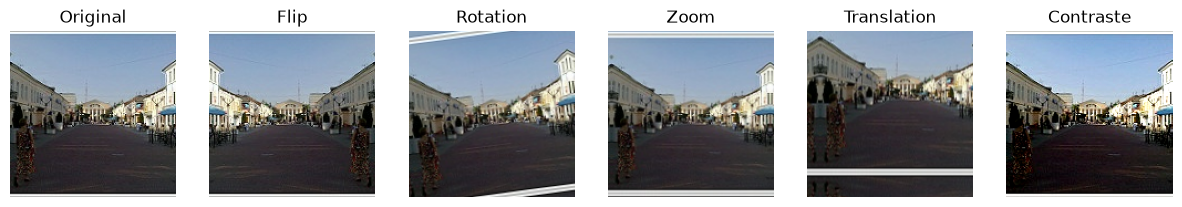

In [24]:
# Une seule image, avec la dimension batch
image = tf.expand_dims(images[0], 0)

transformations = {
    "Flip": layers.RandomFlip("horizontal"),
    "Rotation": layers.RandomRotation(0.2),
    "Zoom": layers.RandomZoom(0.3),
    "Translation": layers.RandomTranslation(0.2, 0.2),
    "Contraste": layers.RandomContrast(0.4),
}

plt.figure(figsize=(15, 3))

plt.subplot(1, 6, 1)
plt.imshow(image[0].numpy().astype("uint8"))
plt.title("Original")
plt.axis("off")

position = 2
for nom, calque in transformations.items():
    resultat = calque(image, training=True)
    plt.subplot(1, 6, position)
    plt.imshow(np.clip(resultat[0].numpy(), 0, 255).astype("uint8"))
    plt.title(nom)
    plt.axis("off")
    position = position + 1

plt.show()

## Étape 8 — Avant / après : la Data Augmentation du projet

**Problème :** combiner les 5 transformations, avec des valeurs **légères** pour ne pas trop déformer les images.

**Explication du code :**
- `keras.Sequential([...])` met les transformations **les unes après les autres**.
- clip force les valeurs à rester entre 0 et 255.
- On applique 8 fois cette augmentation à la **même image** : à chaque fois le résultat est différent.

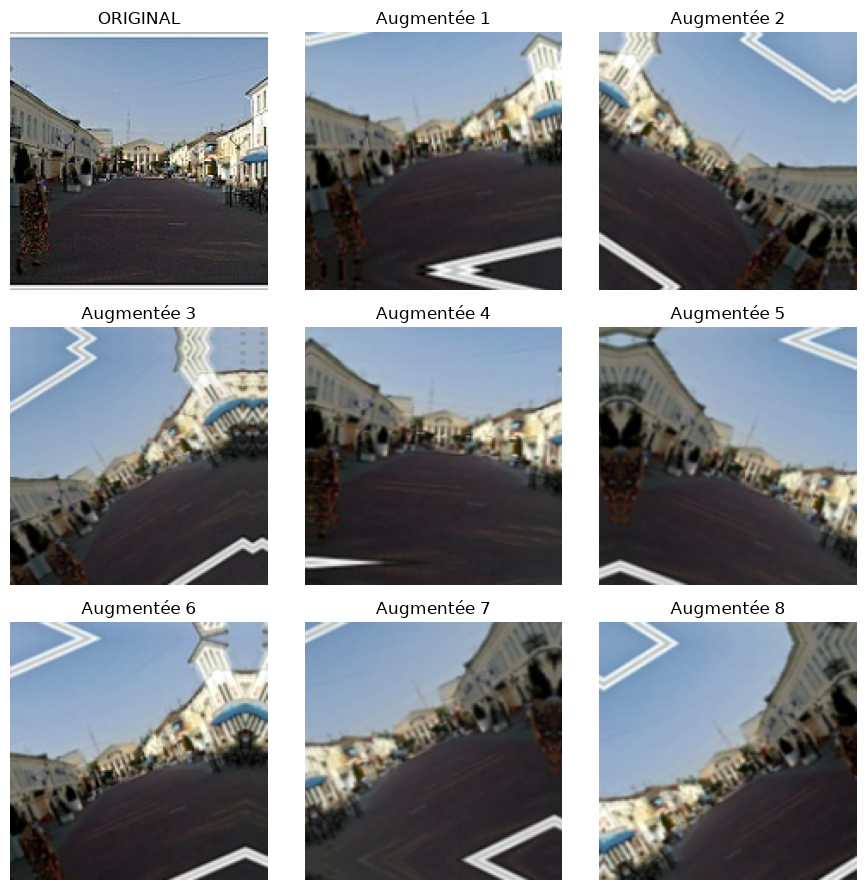

In [25]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1),
])

plt.figure(figsize=(9, 9))

plt.subplot(3, 3, 1)
plt.imshow(image[0].numpy().astype("uint8"))
plt.title("ORIGINAL")
plt.axis("off")

for i in range(8):
    resultat = data_augmentation(image, training=True)
    plt.subplot(3, 3, i + 2)
    plt.imshow(np.clip(resultat[0].numpy(), 0, 255).astype("uint8"))
    plt.title("Augmentée " + str(i + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()

- Test ci-dessous : avec `training=False`, l'image de sortie doit être **identique** à l'image d'entrée (`True`).

In [26]:
sortie = data_augmentation(image, training=False)
print("Image inchangée avec training=False ?", np.allclose(sortie.numpy(), image.numpy()))

Image inchangée avec training=False ? True
